# Project 4

In [2]:
import os, pandas as pd


In [4]:
# get the derm7pt release v0 data from https://derm7pt.com/downloads/ and unzip it to ~/data/derm7pt/release_v0
DIR = os.path.expanduser("~/data/derm7pt/release_v0")
meta = pd.read_csv(os.path.join(DIR, "meta/meta.csv"))

# Same grouping as derm7pt's Derm7PtDatasetGroupInfrequent
def group_diagnosis(d):
    d = str(d).lower()
    if d == "basal cell carcinoma":   return "BCC"
    if "melanoma" in d:               return "MEL"
    if "nevus" in d:                  return "NEV"
    
    if d == "seborrheic keratosis":   return "SK"
    if d in {"dermatofibroma", "lentigo", "melanosis", "miscellaneous", "vascular lesion"}: return "MISC"
    return None                                            # unknown -> check

CONCEPT_MAPS = {
    "pigment_network":       {"absent": 0, "typical": 1, "atypical": 2},
    "blue_whitish_veil":     {"absent": 0, "present": 1},
    "vascular_structures":   {"absent": 0, "arborizing": 1, "comma": 1, "hairpin": 1, "within regression": 1,
                              "wreath": 1, "dotted": 2, "linear irregular": 2},
    "pigmentation":          {"absent": 0, "diffuse regular": 1, "localized regular": 1,
                              "diffuse irregular": 2, "localized irregular": 2},
    "streaks":               {"absent": 0, "regular": 1, "irregular": 2},
    "dots_and_globules":     {"absent": 0, "regular": 1, "irregular": 2},
    "regression_structures": {"absent": 0, "blue areas": 1, "white areas": 1, "combinations": 1},
}
DIAG_CLASSES = ["BCC", "NEV", "MEL", "MISC", "SK"]

df = meta.copy()
df["diag"] = df["diagnosis"].map(group_diagnosis)
df["y"] = df["diag"].map({c: i for i, c in enumerate(DIAG_CLASSES)})
for col, m in CONCEPT_MAPS.items():
    df[col + "_num"] = df[col].str.strip().str.lower().map(m)

# sanity check: nothing should be unmapped
unmapped = {c: df.loc[df[c + "_num"].isna(), c].unique().tolist() for c in CONCEPT_MAPS}
print("unmapped diagnoses:", df.loc[df["diag"].isna(), "diagnosis"].unique())
print("unmapped concepts:", {k: v for k, v in unmapped.items() if v})

# official split
idx = lambda name: pd.read_csv(os.path.join(DIR, f"meta/{name}_indexes.csv"))["indexes"].tolist()
df["split"] = "unused"
df.loc[idx("train"), "split"] = "train"
df.loc[idx("valid"), "split"] = "valid"
df.loc[idx("test"),  "split"] = "test"

print(df["split"].value_counts())
print(pd.crosstab(df["diag"], df["split"]))
df[["case_num", "clinic", "derm", "diag"] + [c + "_num" for c in CONCEPT_MAPS]].head()

unmapped diagnoses: <StringArray>
[]
Length: 0, dtype: str
unmapped concepts: {}
split
train    413
test     395
valid    203
Name: count, dtype: int64
split  test  train  valid
diag                     
BCC      16     19      7
MEL     101     90     61
MISC     40     32     25
NEV     219    256    100
SK       19     16     10


,case_num,clinic,derm,diag,pigment_network_num,blue_whitish_veil_num,vascular_structures_num,pigmentation_num,streaks_num,dots_and_globules_num,regression_structures_num
0,1,NEL/NEL025.JPG,NEL/Nel026.jpg,BCC,0,0,1,0,0,0,0
1,2,NEL/NEL027.JPG,NEL/Nel028.jpg,BCC,0,0,0,0,0,2,0
2,3,NEL/Nel032.jpg,NEL/Nel033.jpg,BCC,0,0,1,0,0,2,0
3,4,NEL/NEL034.JPG,NEL/Nel035.jpg,BCC,0,1,1,0,0,2,1
4,5,NEL/NEL036.JPG,NEL/Nel037.jpg,BCC,0,0,0,2,0,0,0


In [3]:
%pip install git+https://github.com/jeremykawahara/derm7pt.git

  Cloning https://github.com/jeremykawahara/derm7pt.git to /private/var/folders/t7/k_81cy8x6zg28rjf0wl09fl00000gn/T/pip-req-build-clo8pro5
  Running command git clone --filter=blob:none --quiet https://github.com/jeremykawahara/derm7pt.git /private/var/folders/t7/k_81cy8x6zg28rjf0wl09fl00000gn/T/pip-req-build-clo8pro5
  Resolved https://github.com/jeremykawahara/derm7pt.git to commit ce436877573c0a53cfa0d224bda20d9479b795aa
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix th

In [5]:
!pip install --no-deps git+https://github.com/jeremykawahara/derm7pt.git
import os, pandas as pd
from derm7pt.dataset import Derm7PtDatasetGroupInfrequent

DIR = "/content/release_v0"          # with meta/ inside
derm = Derm7PtDatasetGroupInfrequent(
    dir_images=os.path.join(DIR, "images"),
    metadata_df=pd.read_csv(os.path.join(DIR, "meta/meta.csv")),
    train_indexes=list(pd.read_csv(os.path.join(DIR, "meta/train_indexes.csv"))["indexes"]),
    valid_indexes=list(pd.read_csv(os.path.join(DIR, "meta/valid_indexes.csv"))["indexes"]),
    test_indexes=list(pd.read_csv(os.path.join(DIR, "meta/test_indexes.csv"))["indexes"]))

  Cloning https://github.com/jeremykawahara/derm7pt.git to /private/var/folders/t7/k_81cy8x6zg28rjf0wl09fl00000gn/T/pip-req-build-u3bsarv1
  Running command git clone --filter=blob:none --quiet https://github.com/jeremykawahara/derm7pt.git /private/var/folders/t7/k_81cy8x6zg28rjf0wl09fl00000gn/T/pip-req-build-u3bsarv1
  Resolved https://github.com/jeremykawahara/derm7pt.git to commit ce436877573c0a53cfa0d224bda20d9479b795aa
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for derm7pt: filename=derm7pt-0.0.1-py3-none-any.whl size=10384 sha256=4aaab97bb8754369f74e4bd8cc36057ea9bdfa3aa72a1cfc28ea342d778f38e0
  Stored in directory: /private/var/folders/t7/k_81cy8x6zg28rjf0wl09fl00000gn/T/pip-ephem-wheel-cache-ypzyr_mr/wheels/0c/d2/10/f5fb627c4410eb3ef9b6958b0f027b02cc914a9e82924f0867
Successfully built derm7pt


ModuleNotFoundError: No module named 'keras'

['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes']


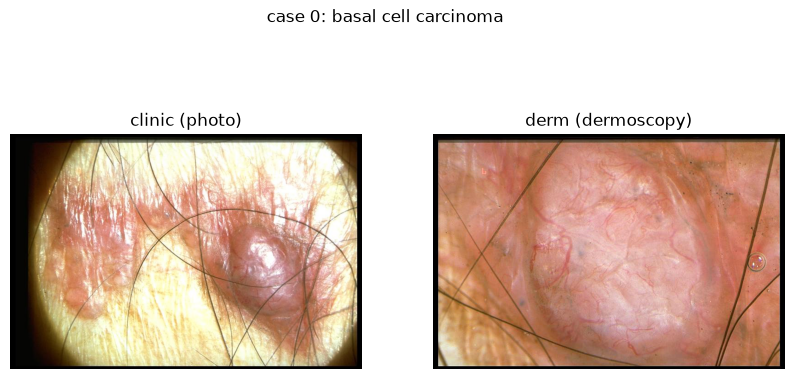

diagnosis                basal cell carcinoma
pigment_network                        absent
blue_whitish_veil                      absent
vascular_structures                arborizing
pigmentation                           absent
streaks                                absent
dots_and_globules                      absent
regression_structures                  absent
Name: 0, dtype: object


In [6]:
import os, pandas as pd, matplotlib.pyplot as plt
from PIL import Image

DIR = os.path.expanduser("~/data/derm7pt/release_v0")
meta = pd.read_csv(os.path.join(DIR, "meta/meta.csv"))
print(meta.columns.tolist())          # see which columns exist

i = 0                                 # change to look at other cases
row = meta.iloc[i]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(Image.open(os.path.join(DIR, "images", row["clinic"]))); ax[0].set_title("clinic (photo)")
ax[1].imshow(Image.open(os.path.join(DIR, "images", row["derm"])));   ax[1].set_title("derm (dermoscopy)")
for a in ax: a.axis("off")
plt.suptitle(f"case {i}: {row['diagnosis']}"); plt.show()
print(row[["diagnosis", "pigment_network", "blue_whitish_veil", "vascular_structures",
           "pigmentation", "streaks", "dots_and_globules", "regression_structures"]])